In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests

url = ("https://archive-api.open-meteo.com/v1/archive"
       "?latitude=28.67&longitude=77.42"
       "&start_date=2015-01-01&end_date=2024-12-31"
       "&daily=temperature_2m_max,temperature_2m_min,temperature_2m_mean,"
       "precipitation_sum,wind_speed_10m_max"
       "&timezone=Asia%2FKolkata")

response = requests.get(url)
data = pd.DataFrame(response.json()['daily'])
data.head()

,time,temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum,wind_speed_10m_max
0,2015-01-01,21.7,11.7,16.3,0.0,9.1
1,2015-01-02,16.6,14.0,15.0,4.2,9.0
2,2015-01-03,18.0,14.0,15.6,0.8,7.9
3,2015-01-04,19.1,10.6,14.6,0.0,13.5
4,2015-01-05,20.7,9.6,14.3,0.0,27.9


In [3]:
print("Rows and columns:", data.shape)
data.info()
print(data.isnull().sum())
data.describe()
data.to_csv("ghaziabad_weather_raw.csv", index=False)

Rows and columns: (3653, 6)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3653 entries, 0 to 3652
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   time                 3653 non-null   object 
 1   temperature_2m_max   3653 non-null   float64
 2   temperature_2m_min   3653 non-null   float64
 3   temperature_2m_mean  3653 non-null   float64
 4   precipitation_sum    3653 non-null   float64
 5   wind_speed_10m_max   3653 non-null   float64
dtypes: float64(5), object(1)
memory usage: 171.4+ KB
time                   0
temperature_2m_max     0
temperature_2m_min     0
temperature_2m_mean    0
precipitation_sum      0
wind_speed_10m_max     0
dtype: int64


In [4]:
data = data.rename(columns={'time': 'date',
                            'temperature_2m_max': 'temp_max',
                            'temperature_2m_min': 'temp_min',
                            'temperature_2m_mean': 'temp_avg',
                            'precipitation_sum': 'rain_mm',
                            'wind_speed_10m_max': 'wind_max'})

data['date'] = pd.to_datetime(data['date'])
data['year'] = data['date'].dt.year
data['month'] = data['date'].dt.month
data['temp_range'] = data['temp_max'] - data['temp_min']
data['is_rainy'] = data['rain_mm'] > 0
data['temp_category'] = np.where(data['temp_avg'] > 30, 'Hot',
                         np.where(data['temp_avg'] > 18, 'Moderate', 'Cold'))
data.head()

,date,temp_max,temp_min,temp_avg,rain_mm,wind_max,year,month,temp_range,is_rainy,temp_category
0,2015-01-01,21.7,11.7,16.3,0.0,9.1,2015,1,10.0,False,Cold
1,2015-01-02,16.6,14.0,15.0,4.2,9.0,2015,1,2.6,True,Cold
2,2015-01-03,18.0,14.0,15.6,0.8,7.9,2015,1,4.0,True,Cold
3,2015-01-04,19.1,10.6,14.6,0.0,13.5,2015,1,8.5,False,Cold
4,2015-01-05,20.7,9.6,14.3,0.0,27.9,2015,1,11.1,False,Cold


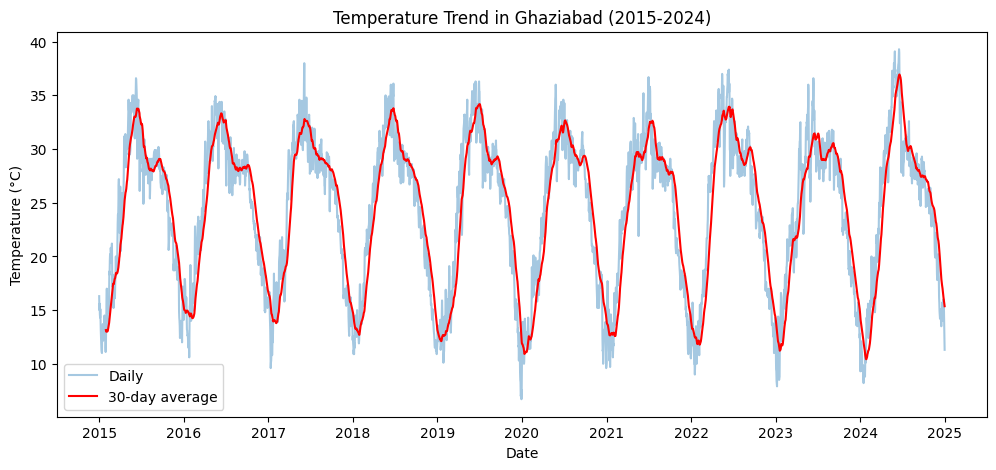

In [5]:
plt.figure(figsize=(12,5))
plt.plot(data['date'], data['temp_avg'], alpha=0.4, label='Daily')
plt.plot(data['date'], data['temp_avg'].rolling(30).mean(), color='red', label='30-day average')
plt.title('Temperature Trend in Ghaziabad (2015-2024)')
plt.xlabel('Date'); plt.ylabel('Temperature (°C)')
plt.legend(); plt.show()

year
2015    24.26
2016    24.94
2017    24.46
2018    24.15
2019    24.00
2020    23.60
2021    24.11
2022    24.56
2023    23.96
2024    24.62
Name: temp_avg, dtype: float64


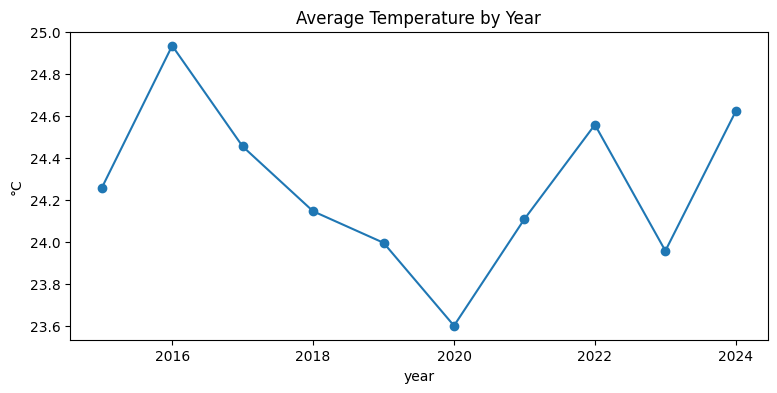

In [6]:
yearly = data.groupby('year')['temp_avg'].mean()
print(yearly.round(2))
yearly.plot(marker='o', figsize=(9,4), title='Average Temperature by Year')
plt.ylabel('°C'); plt.show()

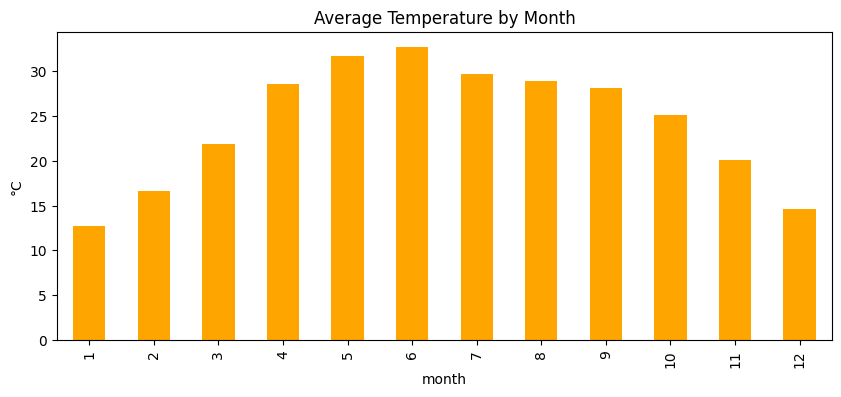

In [7]:
monthly = data.groupby('month')['temp_avg'].mean()
monthly.plot(kind='bar', color='orange', figsize=(10,4))
plt.title('Average Temperature by Month'); plt.ylabel('°C'); plt.show()

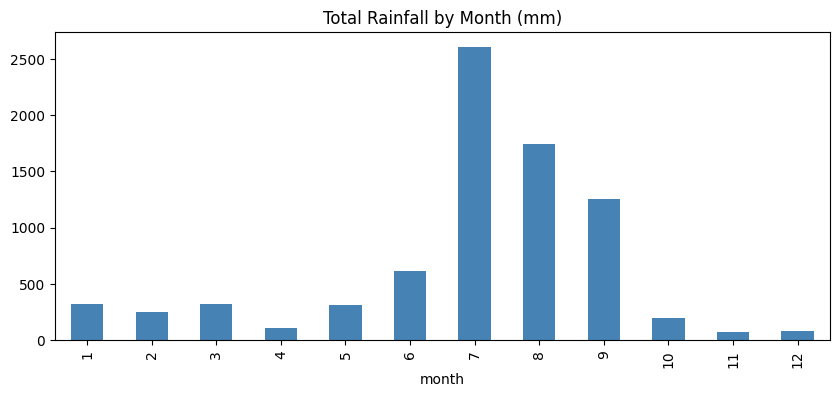

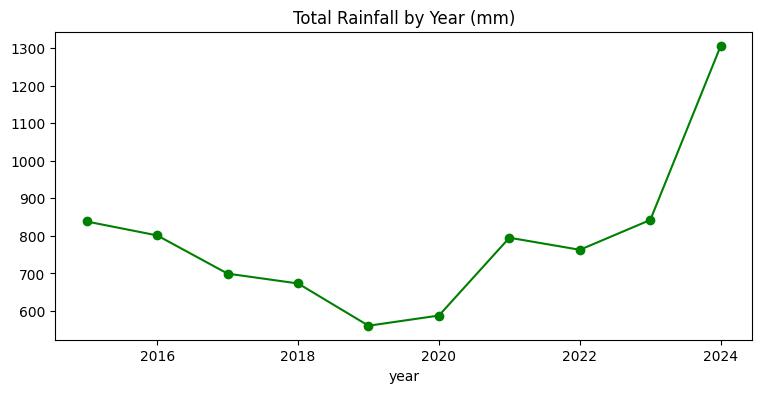

In [8]:
data.groupby('month')['rain_mm'].sum().plot(kind='bar', color='steelblue', figsize=(10,4))
plt.title('Total Rainfall by Month (mm)'); plt.show()

data.groupby('year')['rain_mm'].sum().plot(marker='o', figsize=(9,4), color='green')
plt.title('Total Rainfall by Year (mm)'); plt.show()

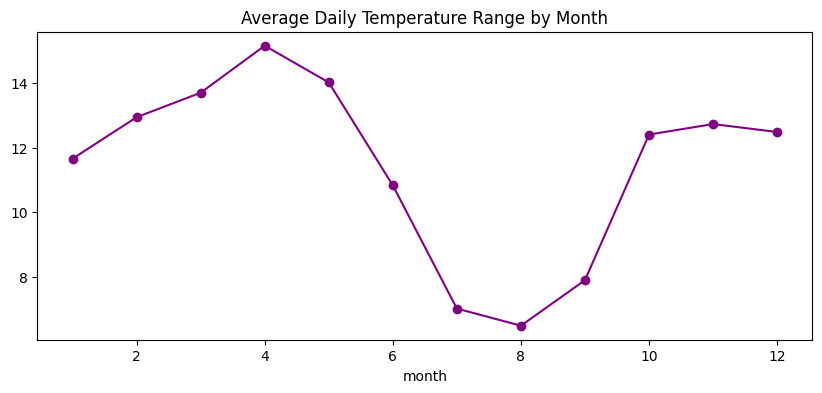

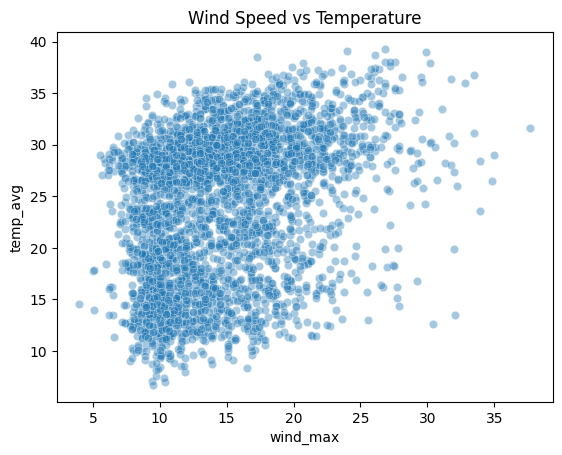

In [9]:
data.groupby('month')['temp_range'].mean().plot(marker='o', figsize=(10,4), color='purple')
plt.title('Average Daily Temperature Range by Month'); plt.show()

sns.scatterplot(x='wind_max', y='temp_avg', data=data, alpha=0.4)
plt.title('Wind Speed vs Temperature'); plt.show()

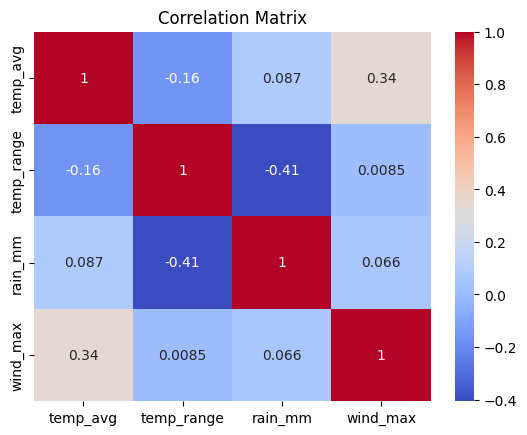

In [10]:
sns.heatmap(data[['temp_avg','temp_range','rain_mm','wind_max']].corr(),
            annot=True, cmap='coolwarm')
plt.title('Correlation Matrix'); plt.show()

In [11]:
print("Hottest month:", monthly.idxmax(), "->", round(monthly.max(), 1), "°C")
print("Coldest month:", monthly.idxmin(), "->", round(monthly.min(), 1), "°C")
print("Warmest year:", yearly.idxmax(), "->", round(yearly.max(), 2), "°C")
print("Coldest year:", yearly.idxmin(), "->", round(yearly.min(), 2), "°C")
print("Rainy days:", data['is_rainy'].sum(), "of", len(data))
print(data['temp_category'].value_counts())

Hottest month: 6 -> 32.8 °C
Coldest month: 1 -> 12.7 °C
Warmest year: 2016 -> 24.94 °C
Coldest year: 2020 -> 23.6 °C
Rainy days: 1293 of 3653
temp_category
Moderate    1970
Cold         890
Hot          793
Name: count, dtype: int64


Conclusion (Ghaziabad, 2015-2024)
Seasonal pattern: Temperature follows a clear yearly cycle. June is the hottest month, with an average of about 32.8°C, and January is the coldest, at about 12.7°C. That is a gap of roughly 20°C between the hottest and coldest months.
Yearly trend: Yearly average temperature stayed in a narrow range, from 23.6°C in 2020 to 24.94°C in 2016. The warmest year is near the start of the period and the coldest is in the middle, so the data does not show a steady warming trend over these 10 years.
Rainfall: Out of 3653 days, 1293 days (about 35%) had some rainfall. This counts any rain above 0 mm, including very light rain. ___ (fill in from your rainfall graph: which month has the most rain, and which year was wettest).
Temperature categories: About 54% of days (1970) were Moderate (18-30°C). Cold days (below 18°C) were 890 (about 24%) and Hot days (above 30°C) were 793 (about 22%). So Ghaziabad has a wide range of temperatures, not a single dominant type of weather.
Other variables: ___ (fill in from your temperature range graph and heatmap: which month has the biggest daily temperature range, and which two variables have the strongest correlation).
Overall: Ghaziabad’s weather is driven mainly by the season. The hot summer, monsoon rain and cold winter repeat every year, while year-to-year change in average temperature is small.